# Configuring the backend

Visisipy performs all optical simulations in a backend, which uses existing optical simulation software to perform the calculations.
Multiple backends are available:

- [**OpticStudio**][opticstudio]: commercial ray tracing software. Visisipy uses [ZOSPy][zospy] to connect with OpticStudio.
- [**Optiland**][optiland]: an open-source Python library for optical simulations.

Backends are 'stateful': they keep track of the current state of the optical system, including the current field and wavelength.
This allows for efficient calculations and reduces the need to repeatedly set up the optical system.
Various optical system properties, for example the fields and wavelengths, are also stored in the backend.

:::{tip}
As a rule of thumb, settings that would be configured in OpticStudio's System Explorer should be configured in the backend.
:::

:::{warning}
Backends may give different results for the same optical system.
Always check if results are consistent with the expected behavior of the optical system.
See [](../examples/Backend%20comparison/backend_comparison.ipynb) for a comparison of the backends.
:::

[zospy]: https://zospy.readthedocs.io/
[opticstudio]: https://www.ansys.com/products/optics/ansys-zemax-opticstudio
[optiland]: https://optiland.readthedocs.io/

## Setting the backend

The preferred backend can be selected using {py:func}`visisipy.set_backend <visisipy.backend.set_backend>`:

In [1]:
import visisipy

visisipy.set_backend("optiland")  # or "opticstudio"

## Updating settings

Settings can be updated using {py:func}`visisipy.update_settings <visisipy.backend.update_settings>`.
Supported parameters are specified by {py:class}`visisipy.backend.BackendSettings`.
Furthermore, some parameters are backend-specific.
For example, the OpticStudio and Optiland backends use different names for the ray aiming method and its parameters, so they have different parameters for configuring ray aiming.


In [2]:
visisipy.update_settings(
    field_type="angle",
    fields=[(0, 0), (0, 30)],
    wavelengths=[0.400, 0.500, 0.600],
    aperture_type="entrance_pupil_diameter",
    aperture_value=1.348,
)

The following settings can be changed:

```{list-table}
:header-rows: 1
:label: backend-settings

* - Setting
  - Description
  - Backends
  - Default

* - ``fields``
  - The fields to be used in the optical system, in degrees for 'angle' fields and millimeters for 'object_height' fields.
  - All
  - ``[(0, 0)]``

* - ``field_type``
  - The type of fields to be used in the optical system.
  - All
  - ``'angle'``

* - ``wavelengths``
  - The wavelengths to be used in the optical system, in microns.
  - All
  - ``[0.543]``

* - ``aperture_type``
  - The type of aperture to be used in the optical system.
  - All
  - ``'float_by_stop_size'``

* - ``aperture_value``
  - The value (e.g. diameter) of the aperture to be used in the optical system.
  - All
  - ``2``

* - ``ray_aiming``
  - The ray aiming method to be used in the optical system. Note: allowed values depend on the backend.
  - All
  - ``'off'`` for OpticStudio, ``'paraxial'`` for Optiland

* - ``ray_aiming_max_iterations``
  - The maximum number of iterations for ray aiming, when using the ``'iterative'`` method.
  - Optiland
  - ``10``

* - ``ray_aiming_tolerance``
  - The tolerance for ray aiming, when using the ``'iterative'`` method.
  - Optiland
  - ``1e-6``

* - ``mode``
  - The OpticStudio connection mode.
  - OpticStudio
  - ``'standalone'``

* - ``zosapi_nethelper``
  - The path to `ZOSAPI_NetHelper.dll` for connecting to OpticStudio.
  - OpticStudio
  - ``None`` (automatic detection)

* - ``opticstudio_directory``
  - The path to the OpticStudio installation directory.
  - OpticStudio
  - ``None`` (automatic detection)

* - ``computation_backend``
  - The computation backend to be used for ray tracing calculations.
  - Optiland
  - ``'numpy'``

* - ``torch_device``
  - The device to be used for ray tracing calculations when using the 'torch' computation backend.
  - Optiland
  - ``'cpu'``

* - ``torch_precision``
  - The precision to be used for ray tracing calculations when using the 'torch' computation backend.
  - Optiland
  - ``'float64'``

* - ``torch_use_grad_mode``
  - Use PyTorch's gradient mode for ray tracing calculations when using the 'torch' computation backend.
  - Optiland
  - ``False``
```

For an overview of all settings, see:

- {py:class}`BackendSettings <visisipy.backend.BackendSettings>` for settings that are common to all backends.
- {py:class}`OpticStudioSettings <visisipy.opticstudio.backend.OpticStudioSettings>` for OpticStudio-specific settings.
- {py:class}`OptilandSettings <visisipy.optiland.backend.OptilandSettings>` for Optiland-specific settings.

### Running Visisipy and OpticStudio side-by-side

OpticStudio has two connection modes, `standalone` and `extension`.
By default, Visisipy connects to OpticStudio in `standalone` mode, which launches an invisible instance of OpticStudio that is entirely controlled by Visisipy.
In `extension` mode, Visisipy connects to an already running instance of OpticStudio.
This mode can be activated by setting the `mode` parameter to `extension` when initializing the OpticStudio backend:

```python
visisipy.set_backend("opticstudio", mode="extension")
```

You can read more about OpticStudio's connection modes in the [ZOSPy documentation](https://zospy.readthedocs.io/en/latest/usage/01_connection.html).

(optiland-gpu)=
### Performing ray tracing on a GPU

Optiland allows to configure the backend for numerical computations.
This backend is also managed through the {py:class}`Optiland backend settings <visisipy.optiland.backend.OptilandSettings>`.
By default, all computations are performed using `numpy`.
To use GPU acceleration, the `torch` computation backend can be selected:

```python
visisipy.set_backend(
    "optiland",
    computation_backend="torch",
    torch_device="cuda",  # or "cpu"
)
```

## Getting the backend

In some advanced cases, it may be necessary to access the backend directly.
The backend can be accessed using {py:func}`visisipy.get_backend <visisipy.backend.get_backend>`.
Note that this function will initialize the default backend if no backend is set.

In [3]:
backend = visisipy.get_backend()

print("Field type:", backend.get_setting("field_type"))  # Get the field type

Field type: angle


## Getting the optical system

It may also be necessary to access the optical system directly, for example to put a camera or a lens in front of the eye model.
Visisipy provides various functions to access the optical system, depending on the backend:

- When using OpticStudio, the optical system can be accessed using {py:func}`visisipy.get_oss <visisipy.backend.get_oss>`.
- When using Optiland, the optical system can be accessed using {py:func}`visisipy.get_optic <visisipy.backend.get_optic>`.

You can read more about this in [](backend_direct.ipynb).

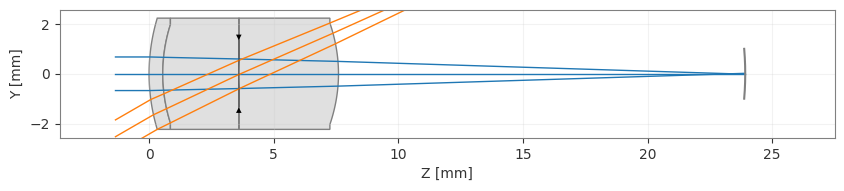

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [4]:
# Create an eye model and draw it
model = visisipy.NavarroEyeModel()
model.build()

visisipy.get_optic().draw()